In [1]:
import pandas as pd, numpy as np
import seaborn as sns, matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
D = '/content/drive/MyDrive/MinneMUDAC 26 for BU/'

fs    = pd.read_excel(D + 'By Organizers/Data/org_FSStats.xlsx')
orgs  = pd.read_excel(D + 'By Organizers/Data/Organization.xlsx')
mb    = pd.read_excel(D + 'By Organizers/Data/marketbucksUsage.xlsx')
calls = pd.read_excel(D + 'By Organizers/Data/Incoming Call.xlsx')
mmg   = pd.read_excel(D + 'MMG_County_MN_2021_2024.xlsx')

fs.shape, orgs.shape, mb.shape, calls.shape, mmg.shape
# (28287, 58) (1202, 68) (13573, 19) (49727, 31) (348, 26)

((28287, 58), (1202, 68), (13573, 19), (49727, 31), (348, 26))

In [3]:
fs.info(), orgs.info(), mb.info(), calls.info(), mmg.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28287 entries, 0 to 28286
Data columns (total 58 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   __ID                 28287 non-null  int64         
 1   _id_site             28287 non-null  float64       
 2   _Year                28287 non-null  int64         
 3   _Month               28287 non-null  int64         
 4   DateForSearch        28287 non-null  datetime64[ns]
 5   zzCreationTS         28287 non-null  object        
 6   zzModificationTS     28287 non-null  object        
 7   AdultsReg            26225 non-null  float64       
 8   ChildrenReg          26101 non-null  float64       
 9   HouseholdsReg        26049 non-null  float64       
 10  IndividualsReg       26260 non-null  float64       
 11  Meals                12806 non-null  float64       
 12  Misc                 0 non-null      float64       
 13  People               0 non-null

(None, None, None, None, None)

In [4]:
empty = fs.columns[fs.notna().sum() == 0]
print(len(empty), list(empty))

fs = fs.drop(columns=empty)
fs.shape                                           # (28287, 34)

24 ['Misc', 'People', 'Snacks', 'ChildrenExtra', 'ChildrenProduce', 'ChildrenHoliday', 'AdultsExtra', 'AdultsProduce', 'AdultsHoliday', 'IndividualsExtra', 'SeniorsExtra', 'SeniorsProduce', 'SeniorsHoliday', 'IndividualsProduce', 'IndividualsHoliday', 'UniqueVisitsExtra', 'UniqueVisitsProduce', 'UniqueVisitsHoliday', 'HouseholdsExtra', 'HouseholdsProduce', 'HouseholdsHoliday', 'PoundsExtra', 'PoundsProduce', 'PoundsHoliday']


(28287, 34)

In [5]:
fs = fs.drop(columns=['SuperShelf'])               # broken: populated on 1 site
orgs.SuperShelfStatus.value_counts(dropna=False)   # the usable one: 63 Certified, 20 In Process, 1 stray

,count
SuperShelfStatus,
NaN,1118
Certified,63
In Process,20
1,1


In [6]:
orgs['SuperShelfStatus'] = orgs.SuperShelfStatus.where(
    orgs.SuperShelfStatus.isin(['Certified', 'In Process']))
orgs.SuperShelfStatus.value_counts(dropna=False)   # 63 / 20, stray -> NaN

,count
SuperShelfStatus,
NaN,1119
Certified,63
In Process,20


### DECISION 1
DateForSearch is the date of record. _Year/_Month disagree with it on 26 rows in the window (month 0 = December of the prior year, month 15 = March of the next). They carry nothing DateForSearch lacks: DateForSearch is populated on all 28,287 rows, and is already parsed as a datetime.

In [7]:
fs = fs.drop(columns=['_Year', '_Month'])
fs.shape, fs.DateForSearch.dtype                   # (28287, 31), datetime64[ns]

((28287, 31), dtype('<M8[ns]'))

In [8]:
mmg.columns = [str(c).strip() for c in mmg.columns]
mmg['fips5'] = mmg.FIPS.astype(str).str.zfill(5)   # FIPS is an int; zero-pad to keep 5 chars

# teammate-built file: Minnesota only, 2021-2024, 87 counties x 4 years
mmg.groupby('Year').agg(counties    = ('fips5', 'nunique'),
                        fi_persons  = ('# of Food Insecure Persons Overall', 'sum'),
                        median_rate = ('Overall Food Insecurity Rate', 'median'))
# 2021  87  342,640  0.069
# 2022  87  509,450  0.100
# 2023  87  581,270  0.111
# 2024  87  636,610  0.123

,counties,fi_persons,median_rate
Year,,,
2021,87,342640,0.069
2022,87,509450,0.100
2023,87,581270,0.111
2024,87,636610,0.123


In [9]:
# Q1 window. The brief's 2026-09-22 update sets the range to 2022 thru 2024.
M = ['HouseholdsReg', 'IndividualsReg', 'PoundsReg']
fsq1 = fs[fs.DateForSearch.dt.year.isin([2022, 2023, 2024])].copy()

print(fsq1.shape)
fsq1.groupby(fsq1.DateForSearch.dt.year)[M].sum()

(18756, 31)


,HouseholdsReg,IndividualsReg,PoundsReg
DateForSearch,,,
2022,1970104.0,5662630.0,1.191605e+08
2023,2790625.0,7743201.0,1.414514e+08
2024,2918714.0,9146694.0,1.578168e+08


### DECISION 2

org_FSStats is one row per site per month, but 63 (site, month) keys appear more than once. Keep the larger row: ordered by IndividualsReg, then PoundsReg, then __ID (latest filed). No summing. Benchmarked against each site's single-row months across 61 keys: max/typical median 0.99, sum/typical median 1.73.

In [10]:
fsq1 = (fsq1
    .sort_values(['_id_site', 'DateForSearch', 'IndividualsReg', 'PoundsReg', '__ID'],
                 ascending=[True, True, False, False, False])
    .drop_duplicates(['_id_site', 'DateForSearch'], keep='first')
    .copy())

bad = fsq1.HouseholdsReg > fsq1.IndividualsReg     # a household holds at least one person
print(fsq1.shape, bad.sum())                       # (18692, 31)  98

(18692, 31) 98


### DECISION 3
Look at the 98 impossible rows before changing anything


In [11]:
site_ratio = (fsq1[~bad].groupby('_id_site')[['IndividualsReg', 'HouseholdsReg']].sum()
                        .pipe(lambda g: g.IndividualsReg / g.HouseholdsReg))

bad_tbl = fsq1[bad].copy()
bad_tbl['site_ratio'] = bad_tbl._id_site.map(site_ratio).round(2)
bad_tbl['overshoot']  = (bad_tbl.HouseholdsReg /
                         bad_tbl.IndividualsReg.replace(0, np.nan)).round(2)

bad_tbl[['_id_site', 'DateForSearch', 'County', 'HouseholdsReg', 'IndividualsReg',
         'PoundsReg', 'site_ratio', 'overshoot']].sort_values('overshoot', ascending=False)
# 45 rows in 2022, 23 in 2023, 30 in 2024

,_id_site,DateForSearch,County,HouseholdsReg,IndividualsReg,PoundsReg,site_ratio,overshoot
9567,1197.0,2023-07-01,Waseca,273385.0,646.0,12053.0,2.01,423.20
17376,1219.0,2024-11-01,Hennepin-Minneapolis,2202.0,98.0,94686.0,2.51,22.47
14179,15306.0,2024-04-01,Dakota,3257.0,371.0,3257.0,4.42,8.78
3624,14681.1,2022-02-01,Hennepin-Suburbs,3828.0,699.0,15514.0,3.27,5.48
5774,1267.0,2022-12-01,Hennepin-Minneapolis,500.0,104.0,7380.0,2.49,4.81
...,...,...,...,...,...,...,...,...
11605,15349.0,2023-11-01,Hennepin-Minneapolis,2753.0,2752.0,11572.0,1.89,1.00
12827,13836.0,2024-01-01,McLeod,706.0,0.0,34900.0,2.74,NaN
12828,14621.0,2024-01-01,McLeod,74.0,0.0,2543.0,1.83,NaN
7487,14919.0,2023-03-01,Beltrami,22.0,0.0,595.0,0.33,NaN


### DECISION 3a

Site 1197 (Waseca) 2023-07 reads 273,385 households against 646 individuals. Its June is 285 and its August is 338, so set the midpoint, 311, by hand. Flagged separately so the ratio rule in the next cell never overwrites it.

In [12]:
mask = (fsq1._id_site == 1197.0) & (fsq1.DateForSearch == '2023-07-01')
fsq1['hh_imputed'] = False
fsq1.loc[mask, 'HouseholdsReg'] = 311
fsq1.loc[mask, 'hh_imputed']    = True
print(mask.sum())

1


### DECISION 3b

Rebuild households on the rest from IndividualsReg and a persons-per-household ratio: the site's own, else its county's, else statewide. A ratio below 1.5 is impossible as an average, so it falls through to the next tier.

In [13]:
def ratio(df, key):
    g = df.groupby(key)[['IndividualsReg', 'HouseholdsReg']].sum()
    r = g.IndividualsReg / g.HouseholdsReg
    return r.where(r >= 1.5)

clean    = fsq1[~bad]                              # excludes all 98, Waseca included
site_r   = ratio(clean, '_id_site')
county_r = ratio(clean, 'County')
state_r  = clean.IndividualsReg.sum() / clean.HouseholdsReg.sum()     # 3.0697

fixable = bad & (fsq1.IndividualsReg > 0) & ~fsq1.hh_imputed          # 93
r = (fsq1._id_site.map(site_r)
         .fillna(fsq1.County.map(county_r))
         .fillna(state_r))

fsq1['hh_adjusted'] = bad      # all 98 suspect as received; bool, so no .loc needed
fsq1.loc[fixable, 'HouseholdsReg'] = (fsq1.loc[fixable, 'IndividualsReg'] / r[fixable]).round()

print(pd.Series(np.where(fsq1._id_site.map(site_r).notna(), 'site',
                np.where(fsq1.County.map(county_r).notna(), 'county', 'state'))[fixable]
      ).value_counts().to_dict())                  # {'site': 56, 'county': 36, 'state': 1}

{'site': 56, 'county': 36, 'state': 1}


In [14]:
print(fsq1.hh_adjusted.sum())                      # 98  suspect as received
print(fsq1.hh_imputed.sum())                       # 1   Waseca, set by hand
print(fixable.sum())                               # 93  rewritten from a ratio
print((bad & (fsq1.IndividualsReg == 0)).sum())    # 4   left alone -> decision 4

fsq1.groupby(fsq1.DateForSearch.dt.year)[M].sum()
# after decisions 1-3:
# 2022  1,937,451  5,650,600  118,775,916.37      households -1.41% vs as received
# 2023  2,506,996  7,743,036  141,446,461.50      households -10.16%
# 2024  2,900,331  9,142,235  157,714,352.54      households -0.57%

98
1
93
4


,HouseholdsReg,IndividualsReg,PoundsReg
DateForSearch,,,
2022,1937451.0,5650600.0,1.187759e+08
2023,2506996.0,7743036.0,1.414465e+08
2024,2900331.0,9142235.0,1.577144e+08


In [15]:
# Consolidate the sub-county labels. MMG is county-level, so Hennepin and Ramsey have to
# exist as single counties — but keep the original label too, it's the only urban/suburban
# split anywhere in this data.
FIX = {'Hennepin-Minneapolis': 'Hennepin', 'Hennepin-Suburbs': 'Hennepin',
       'Ramsey-Saint Paul':    'Ramsey',   'Ramsey-Suburbs':   'Ramsey',
       'Lac Qui Parle':        'Lac qui Parle',
       'Saint Louis':          'St. Louis'}

label = fsq1['County' if 'County' in fsq1.columns else 'county_detail']
if isinstance(label, pd.DataFrame):          # cleans up the duplicate from the bad cell
    label = label.iloc[:, 0]
fsq1 = fsq1.drop(columns=[c for c in ['County', 'county', 'county_detail']
                          if c in fsq1.columns])
fsq1['county_detail'] = label                # Hennepin-Suburbs
fsq1['county']        = label.replace(FIX)   # Hennepin

# D9 — sites 1066 (Anoka) and 1261 (Shakopee) were relabeled Hennepin-Suburbs on
# 2024-01-01 with no change of address, active status or activity. Both sites' City
# field and block_geoid county FIPS (27003, 27139) contradict the label. county_detail
# keeps the label as reported; county carries the geographic truth.
RELABELED = {1066.0: 'Anoka', 1261.0: 'Scott'}
corrected = fsq1._id_site.map(RELABELED)
fsq1['county_corrected'] = corrected.notna() & (corrected != fsq1.county)
fsq1['county'] = corrected.fillna(fsq1.county)
print('D9 rows corrected:', int(fsq1.county_corrected.sum()))   # 24

# MMG carries its own FIPS column, so the name-to-FIPS map needs no external source.
fips = (mmg.assign(c=mmg['County, State'].str.replace(' County, Minnesota', '', regex=False))
            .drop_duplicates('c').set_index('c').fips5)
fsq1['county_fips'] = fsq1.county.map(fips)

print(fsq1.county.nunique(), fsq1.columns.duplicated().sum())        # 86  0
print(fsq1.county_fips.notna().sum(), fsq1.county.notna().sum())     # should match

D9 rows corrected: 24
86 0
18572 18572


In [16]:
recover = {15362.0: 'Rice', 15363.0: 'Rice', 15218.0: 'Cass'}
fill = fsq1._id_site.map(recover)
fsq1['county'] = fsq1.county.fillna(fill)
fsq1['county_unassigned'] = fsq1.county.isna()      # 108 rows, excluded from county work
print(fsq1.county.isna().sum())                     # 108

90


### D6
Three sites can be located from the roster; 39 cannot be located at all. Nothing is dropped: unlocatable rows stay in fsq1 behind a flag so county figures reconcile back to the source file.


In [17]:
RECOVER = {15362.0: 'Rice',   # roster: Northfield, 55057, block_geoid 271310705032009
           15363.0: 'Rice',   # roster: Faribault,  55021, block_geoid 271310709011016
           15218.0: 'Cass'}   # roster: block_geoid 270219606001067 (files zeros all 18 months)

fsq1['county']            = fsq1.county.fillna(fsq1._id_site.map(RECOVER))
fsq1['county_fips']       = fsq1.county.map(fips)
fsq1['county_unassigned'] = fsq1.county.isna()
fsq1['year']              = fsq1.DateForSearch.dt.year

print(fsq1.county_unassigned.sum(),                               # 90
      fsq1.loc[fsq1.county_unassigned, '_id_site'].nunique())     # 39

90 39


In [18]:
M = ['HouseholdsReg', 'IndividualsReg', 'PoundsReg']

county_year = (fsq1[~fsq1.county_unassigned]
               .groupby(['county', 'county_fips', 'year'], as_index=False)[M].sum())
unassigned  = fsq1[fsq1.county_unassigned].groupby('year')[M].sum()

for c in M:                                    # counties + unassigned must equal the window
    a, b, t = county_year[c].sum(), unassigned[c].sum(), fsq1[c].sum()
    assert np.isclose(a + b, t), c
    print(f"{c:16s} counties {a:>15,.2f} + unassigned {b:>12,.2f} = window {t:>15,.2f}")

print(len(county_year), county_year.county.nunique())   # 258 rows, 86 counties
unassigned

HouseholdsReg    counties    7,264,066.00 + unassigned    80,712.00 = window    7,344,778.00
IndividualsReg   counties   22,309,847.00 + unassigned   226,024.00 = window   22,535,871.00
PoundsReg        counties  414,239,263.29 + unassigned 3,697,467.12 = window  417,936,730.41
258 86


,HouseholdsReg,IndividualsReg,PoundsReg
year,,,
2023,32712.0,88960.0,1461149.00
2024,48000.0,137064.0,2236318.12


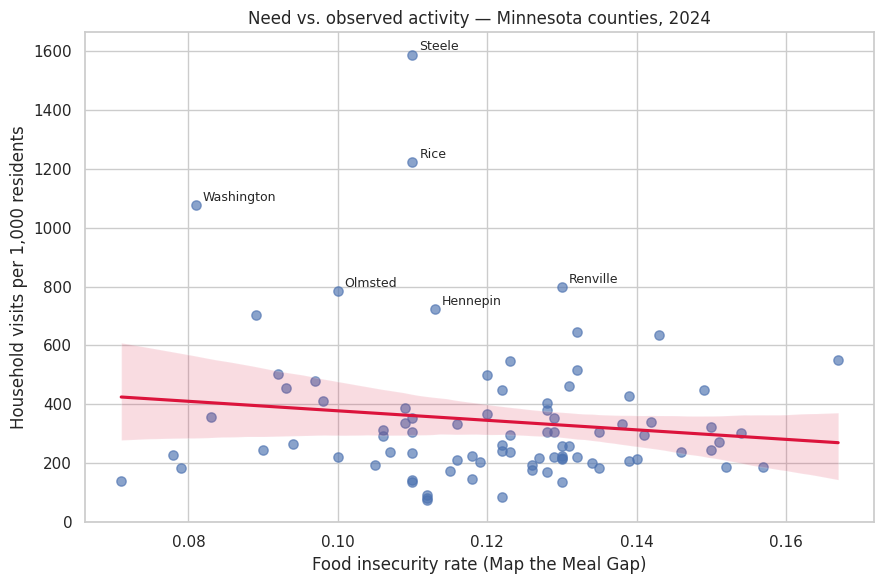

In [19]:
mmg_s = (mmg.assign(county=mmg['County, State'].str.replace(' County, Minnesota', '', regex=False))
            .rename(columns={'Year': 'year',
                             '# of Food Insecure Persons Overall': 'fi_persons',
                             'Overall Food Insecurity Rate': 'fi_rate'})
            [['county', 'year', 'fi_persons', 'fi_rate']])

p = county_year.merge(mmg_s, on=['county', 'year'])
p['population']   = p.fi_persons / p.fi_rate          # MMG's own implied denominator
p['visits_per1k'] = p.HouseholdsReg / p.population * 1000

s = p[(p.year == 2024) & (p.HouseholdsReg > 0)]

sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(9, 6))
sns.regplot(data=s, x='fi_rate', y='visits_per1k', ax=ax,
            scatter_kws=dict(s=45, alpha=.65), line_kws=dict(color='crimson'))
for _, r in s.nlargest(6, 'visits_per1k').iterrows():
    ax.annotate(r.county, (r.fi_rate, r.visits_per1k),
                xytext=(5, 3), textcoords='offset points', fontsize=9)
ax.set(xlabel='Food insecurity rate (Map the Meal Gap)',
       ylabel='Household visits per 1,000 residents',
       title='Need vs. observed activity — Minnesota counties, 2024')
plt.tight_layout()

In [27]:
# ── A8: county characteristics that explain the Q1 gap ────────────────────────
# Answers John Hogue's Zoom 2 question: poverty rate, rural share, distance to
# nearest food shelf, SNAP enrollment (+ no-vehicle share, hub concentration).
# DV = residual of log(people served) on log(food-insecure persons), 2024.
# Tract traits from USDA ERS SRAM 2025 via VG's Q8 table, population-weighted.

import numpy as np, pandas as pd, statsmodels.api as sm

Q8_PATH = '/content/drive/MyDrive/MinneMUDAC 26 for BU/VG/Q8/Q8_outputs/q8_tract_table.csv'   # e.g. D + 'VG/Q8/Q8_outputs/q8_tract_table.csv'

if Q8_PATH:
    t = pd.read_csv(Q8_PATH)
else:
    from google.colab import files
    t = pd.read_csv(next(iter(files.upload())))

def col(df, *names):
    """Return the first column that exists, else None."""
    for n in names:
        if n in df.columns:
            return n
    return None

C = {k: col(t, *v) for k, v in {
    'geoid':   ('GEOID', 'tract'),
    'pop':     ('POP2020', 'population'),
    'poor':    ('pop_poverty', 'people in poverty'),
    'poverty': ('PovertyRate', 'poverty %'),
    'vehicle': ('pct_no_vehicle', '% no vehicle'),
    'snap':    ('pct_snap_hh', '% SNAP households'),
    'dist':    ('mi_foodshelf', 'miles to food shelf'),
    'urban':   ('Urban', 'urban'),
}.items()}
missing = [k for k, v in C.items() if v is None]
if missing:
    raise KeyError(f'not found: {missing}\navailable: {sorted(t.columns)}')

t = t.copy()
t['fips5'] = t[C['geoid']].astype(str).str.zfill(11).str[:5]
w = t[C['pop']].fillna(0)

def wmean(s):
    s = pd.to_numeric(s, errors='coerce')
    ok = s.notna() & (w > 0)
    return (s[ok] * w[ok]).groupby(t.fips5[ok]).sum() / w[ok].groupby(t.fips5[ok]).sum()

traits = pd.DataFrame({
    'poverty_rate':     wmean(t[C['poverty']]),
    'rural_share':      1 - wmean(t[C['urban']]),
    'snap_share':       wmean(t[C['snap']]),
    'no_vehicle_share': wmean(t[C['vehicle']]),
    'dist_to_shelf_mi': wmean(t[C['dist']]),
}).reset_index(names='fips5')

# ── dependent variable: 2024 level residual, same basis as the slide 3 chart ──
d = p[(p.year == 2024) & (p.fi_persons > 0) & (p.IndividualsReg > 0)].copy()
x, y = np.log(d.fi_persons.values), np.log(d.IndividualsReg.values)
b1, b0 = np.polyfit(x, y, 1)
d['resid'] = y - (b0 + b1 * x)

d['fips5'] = d.county_fips.astype(str).str.zfill(5)
m = d.merge(traits, on='fips5', how='left')
m['hub_concentration'] = m['top_site_share'] if 'top_site_share' in m.columns else np.nan

s24 = fsq1[(fsq1.DateForSearch.dt.year == 2024) & (~fsq1.county_unassigned)]
site = s24.groupby(['county', '_id_site']).HouseholdsReg.sum()
hub = (site.groupby('county').max() / site.groupby('county').sum())
m['hub_concentration'] = m.county.map(hub)
print('hub_concentration merged:', m.hub_concentration.notna().sum())

TRAITS = ['poverty_rate', 'rural_share', 'snap_share',
          'no_vehicle_share', 'dist_to_shelf_mi', 'hub_concentration']
have = [c for c in TRAITS if m[c].notna().sum() >= 60]
print(f'counties in panel: {len(d)} | merged traits: {m[have].notna().all(axis=1).sum()}')
print('dropped for sparsity:', [c for c in TRAITS if c not in have] or 'none')

s = m.dropna(subset=have + ['resid'])
Z = (s[have] - s[have].mean()) / s[have].std(ddof=0)
fit = sm.OLS(s.resid, sm.add_constant(Z)).fit(cov_type='HC3')

out = pd.DataFrame({
    'beta': fit.params, 'se': fit.bse, 'p': fit.pvalues
}).drop(index='const')
out['pct_per_SD'] = (np.exp(out.beta) - 1) * 100
out['1 SD ='] = [s[c].std(ddof=0) for c in out.index]
print(f'\nn = {int(fit.nobs)}   R2 = {fit.rsquared:.3f}   HC3 robust SEs')
print(out.sort_values('p').round(3).to_string())

sig = out[out.p < .05].sort_values('p')
print('\n--- for the slide ---')
if len(sig):
    for v, r in sig.iterrows():
        print(f'{v}: {r.pct_per_SD:+.0f}% per 1 SD ({r["1 SD ="]:.1f} units), p = {r.p:.3f}')
else:
    print('no trait significant at p < .05 — A8 has no finding to report')

hub_concentration merged: 86
counties in panel: 86 | merged traits: 86
dropped for sparsity: none

n = 86   R2 = 0.102   HC3 robust SEs
                    beta     se      p  pct_per_SD  1 SD =
dist_to_shelf_mi  -0.188  0.088  0.032     -17.170   2.164
rural_share        0.086  0.080  0.281       8.984   0.292
poverty_rate      -0.070  0.091  0.440      -6.752   2.838
snap_share        -0.049  0.085  0.561      -4.825   2.933
hub_concentration  0.031  0.083  0.709       3.128   0.247
no_vehicle_share   0.008  0.082  0.927       0.755   1.704

--- for the slide ---
dist_to_shelf_mi: -17% per 1 SD (2.2 units), p = 0.032


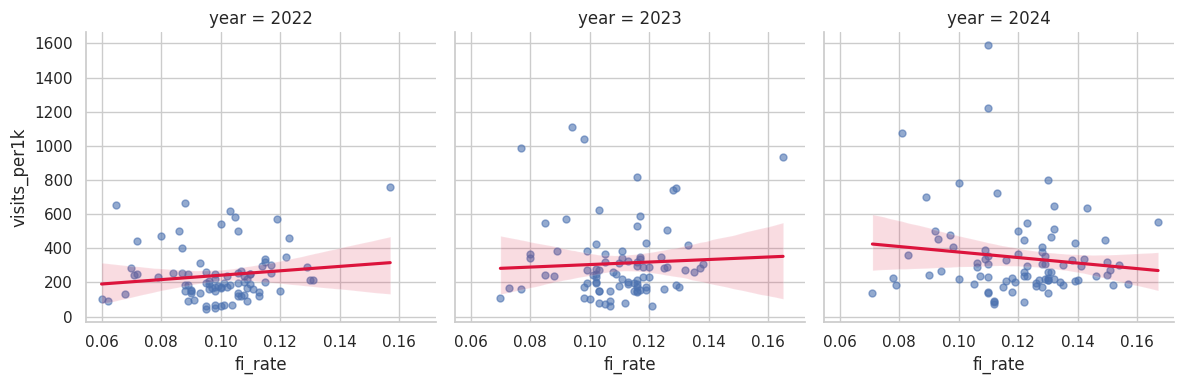

In [20]:
sns.lmplot(data=p[p.HouseholdsReg > 0], x='fi_rate', y='visits_per1k', col='year',
           height=4, scatter_kws=dict(s=25, alpha=.6), line_kws=dict(color='crimson'))

**Each dot is one Minnesota county. There are 86 of them in each panel; the 87th, Wilkin, has no food shelf activity at all and can't be plotted.**

**The horizontal axis is *need*** — Feeding America's estimated food insecurity rate for that county, from Map the Meal Gap. Further right means a larger share of residents are food insecure. The range runs from about 7% to 17%.

**The vertical axis is *observed demand*** — household visits to that county's food shelves, divided by the county's population, times 1,000. Dividing by population is what makes a small county comparable to Hennepin; without it the chart would just rank counties by size.

**The red line is the *average relationship across all 86 counties*** — the best straight-line fit of activity against need. **If need drove activity, it would slope clearly upward.**

**The pale band around the line is the *95% confidence interval for where that line sits.*** A wide band means the line's position is uncertain, which is itself a result: **the relationship is weak.**

####**Vertical distance from the line is the finding.** A dot well above the line is a county with far more food shelf activity than its need level predicts; well below means far less. That distance, divided by its standard error, is the t-value used to flag outliers.

**Three panels, three separate years** — 2022, 2023, 2024 — not a time series. Map the Meal Gap's own FAQ warns that its county estimates are built to compare counties within a year, not a county against itself across years. A county that sits off the line in all three panels is a real finding; one that appears in a single panel is noise.

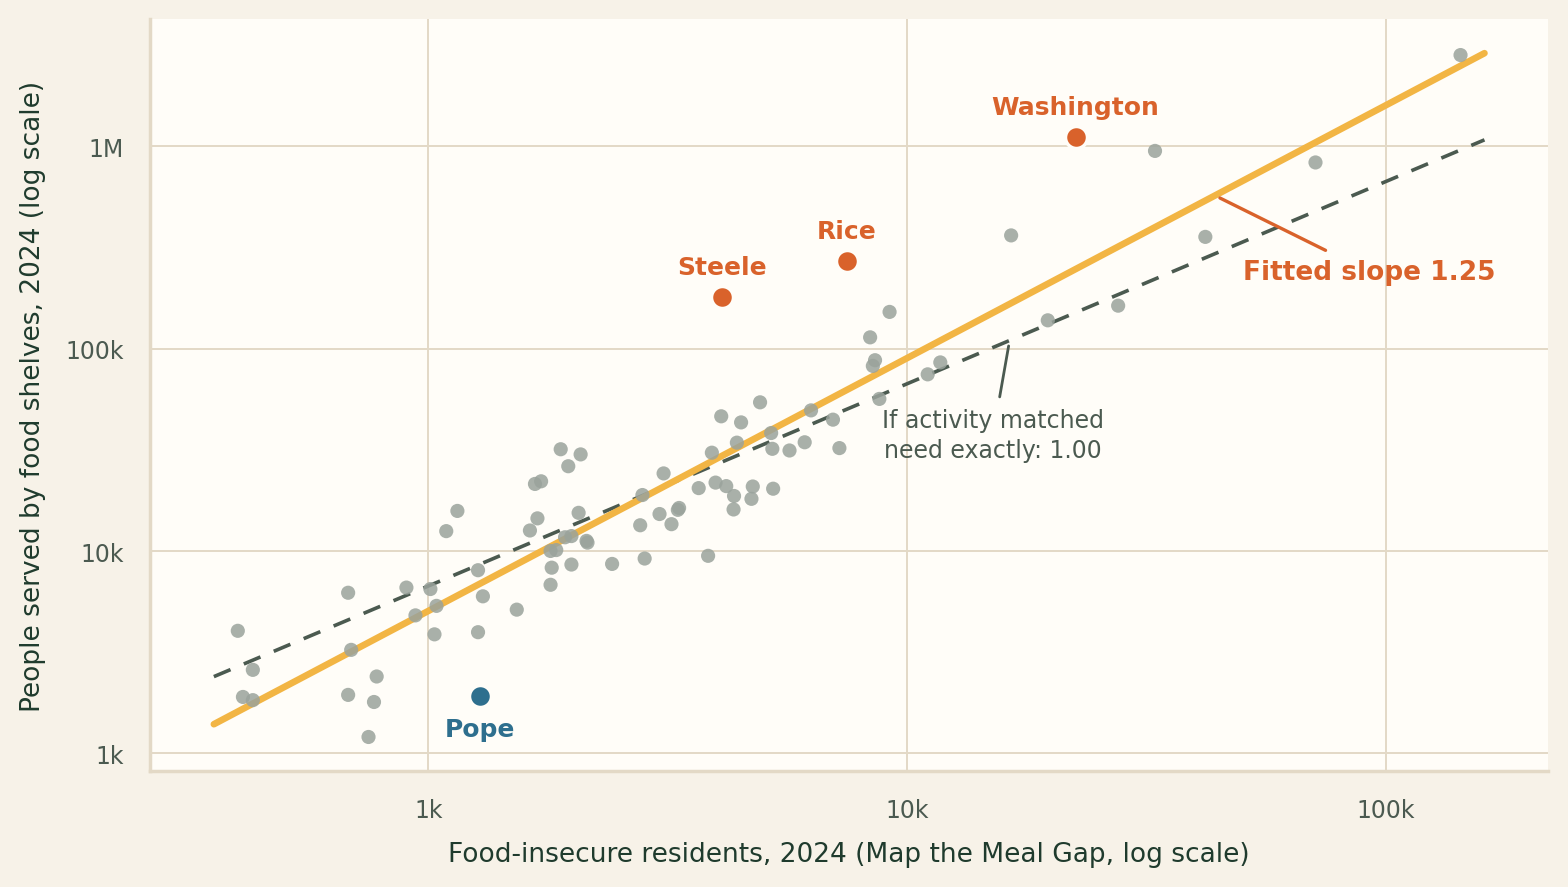

n=86  slope=1.250  r=0.926


In [21]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

GREEN, ORANGE, AMBER = '#1F3B2D', '#D9622B', '#F2B544'
SAND, CREAM, CARD, MUTED = '#E3D9C6', '#F7F2E8', '#FFFDF8', '#4B5A50'
BLUE, GREY = '#2E6F8E', '#9AA39C'

plt.rcParams.update({
    'font.family': ['Source Sans 3', 'Source Sans Pro', 'DejaVu Sans'],
    'text.color': GREEN, 'axes.labelcolor': GREEN,
    'xtick.color': MUTED, 'ytick.color': MUTED,
})

d = p[(p.year == 2024) & (p.fi_persons > 0) & (p.IndividualsReg > 0)].copy()
x, y = np.log10(d.fi_persons.values), np.log10(d.IndividualsReg.values)
b1, b0 = np.polyfit(x, y, 1)
xs = np.linspace(x.min() - .05, x.max() + .05, 100)

fig, ax = plt.subplots(figsize=(8, 4.6), dpi=200)
fig.patch.set_facecolor(CREAM); ax.set_facecolor(CARD)

# --- scale FIRST, before any locator or formatter ---
ax.set_xscale('log'); ax.set_yscale('log')

ax.plot(10**xs, 10**(b0 + b1*xs), color=AMBER, lw=2.4, zorder=3)
ax.plot(10**xs, 10**(y.mean() + 1.0*(xs - x.mean())),
        color=MUTED, lw=1.3, ls=(0, (5, 4)), zorder=2)

ax.scatter(d.fi_persons, d.IndividualsReg, s=26, color=GREY,
           alpha=.85, edgecolor='none', zorder=4)

for names, col, dy, va in [(['Steele','Rice','Washington'], ORANGE, 1.22, 'bottom'),
                           (['Pope'],                        BLUE,   0.78, 'top')]:
    sel = d[d.county.isin(names)]
    ax.scatter(sel.fi_persons, sel.IndividualsReg, s=62, color=col,
               edgecolor=CARD, lw=1.2, zorder=6)
    for _, r in sel.iterrows():
        ax.annotate(r.county, (r.fi_persons, r.IndividualsReg * dy),
                    color=col, fontsize=9, fontweight='bold',
                    ha='center', va=va, zorder=7)

# --- tick labels: 1k / 10k / 100k / 1M ---
def kfmt(v, _):
    if v >= 1e6: return f'{v/1e6:g}M'
    if v >= 1e3: return f'{v/1e3:g}k'
    return f'{v:g}'

for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_locator(LogLocator(base=10))
    axis.set_major_formatter(FuncFormatter(kfmt))
    axis.set_minor_formatter(NullFormatter())

ax.set_xlabel('Food-insecure residents, 2024 (Map the Meal Gap, log scale)',
              fontsize=9.5, labelpad=7)
ax.set_ylabel('People served by food shelves, 2024 (log scale)',
              fontsize=9.5, labelpad=7)
ax.grid(True, which='major', color=SAND, lw=.7, zorder=0)
ax.grid(False, which='minor')
for sp in ('top','right'): ax.spines[sp].set_visible(False)
for sp in ('left','bottom'): ax.spines[sp].set_color(SAND)
ax.tick_params(labelsize=8.5)

k = 78
ax.annotate(f'Fitted slope {b1:.2f}', xy=(10**xs[k], 10**(b0 + b1*xs[k])),
            xytext=(10, -30), textcoords='offset points',
            color=ORANGE, fontsize=9.5, fontweight='bold',
            arrowprops=dict(arrowstyle='-', color=ORANGE, lw=1.2))
ax.annotate('If activity matched\nneed exactly: 1.00',
            xy=(10**xs[62], 10**(y.mean() + 1.0*(xs[62] - x.mean()))),
            xytext=(-6, -42), textcoords='offset points', ha='center',
            color=MUTED, fontsize=8.5, linespacing=1.3,
            arrowprops=dict(arrowstyle='-', color=MUTED, lw=1))

plt.tight_layout()
plt.savefig(D + 'q1_scatter_2024.png', dpi=200, facecolor=CREAM, bbox_inches='tight')
plt.show()
print(f'n={len(d)}  slope={b1:.3f}  r={np.corrcoef(x,y)[0,1]:.3f}')

In [22]:
import numpy as np
d = p[(p.year == 2024) & (p.fi_persons > 0)].copy()

print('=== slope and r, 2024 ===')
for lab, col in [('visits', 'HouseholdsReg'), ('people', 'IndividualsReg'), ('pounds', 'PoundsReg')]:
    dd = d[d[col] > 0]
    x, y = np.log10(dd.fi_persons.values), np.log10(dd[col].values)
    b1, b0 = np.polyfit(x, y, 1)
    res = y - (b0 + b1*x); se = np.sqrt((res@res/(len(x)-2)) / ((x-x.mean())@(x-x.mean())))
    print(f'  {lab:7} n={len(dd):3d}  r={np.corrcoef(x,y)[0,1]:.3f}  slope={b1:.3f}  t vs 1.0={(b1-1)/se:+.2f}')

print('\n=== D9 landed? ===')
for c in ['Scott', 'Anoka', 'Hennepin']:
    print(f'  {c:9} {int(d.loc[d.county==c, "IndividualsReg"].item()):>10,}')
print('  expect  Scott 74,723 | Anoka 950,677 | Hennepin 2,831,042')

print('\n=== per food-insecure person, 2024 ===')
for lab, col in [('visits', 'HouseholdsReg'), ('people', 'IndividualsReg'), ('pounds', 'PoundsReg')]:
    dd = d[d[col] > 0]
    print(f'  r(fi_rate, {lab} per FI person) = {np.corrcoef(dd.fi_rate, dd[col]/dd.fi_persons)[0,1]:+.3f}')

print('\n=== Scott off the list, Pope still on it? ===')
dd = d[d.IndividualsReg > 0]
x, y = np.log10(dd.fi_persons.values), np.log10(dd.IndividualsReg.values)
b1, b0 = np.polyfit(x, y, 1)
t = (y - (b0 + b1*x)); t = t / t.std(ddof=2)
r = dd.assign(t=t)[['county','t']].set_index('county').t
print(f'  Scott {r["Scott"]:+.2f}   Pope {r["Pope"]:+.2f}')
print(f'  counties below -2: {sorted(r[r < -2].index.tolist())}')
print(f'  counties above +2: {sorted(r[r > 2].index.tolist())}')

print('\n=== Pope lowest in state? ===')
pf = (dd.IndividualsReg / dd.fi_persons).rank()
print(f'  Pope rank {int(pf[dd.county.eq("Pope")].item())} of {len(dd)}  (1 = lowest)')

=== slope and r, 2024 ===
  visits  n= 86  r=0.925  slope=1.190  t vs 1.0=+3.55
  people  n= 86  r=0.926  slope=1.250  t vs 1.0=+4.51
  pounds  n= 86  r=0.939  slope=1.190  t vs 1.0=+4.00

=== D9 landed? ===
  Scott         74,723
  Anoka        950,677
  Hennepin   2,831,042
  expect  Scott 74,723 | Anoka 950,677 | Hennepin 2,831,042

=== per food-insecure person, 2024 ===
  r(fi_rate, visits per FI person) = -0.341
  r(fi_rate, people per FI person) = -0.348
  r(fi_rate, pounds per FI person) = -0.362

=== Scott off the list, Pope still on it? ===
  Scott -0.53   Pope -2.17
  counties below -2: ['Pope']
  counties above +2: ['Rice', 'Steele', 'Washington']

=== Pope lowest in state? ===
  Pope rank 1 of 86  (1 = lowest)
